# Quantum GNN on a real IBM quantum computer

Notebook 06 tested the trained quantum GNN on IBM's *noise model* of a Heron chip. This notebook runs the **same trained circuits on a real IBM quantum processor**.

| Step | What happens |
|---|---|
| 1. Setup | Load the trained 75-parameter model and the data, connect to IBM Quantum |
| 2. Circuits | Build one circuit per molecule (same export as notebook 06) and compile it for the chosen device |
| 3. Run | Submit **one** job: calibration molecules (from the training set) + test molecules |
| 4. Analyse | Raw hardware prediction, then refit only the 3-number readout head on the calibration molecules |
| 5. Save | `results/ibm_hardware_results.json` (summary) and `results/ibm_hardware_counts.json` (raw counts) |

**Budget.** With the defaults (30 + 30 molecules, 1,024 shots) the job is small: about 60 short circuits. The notebook prints the quantum time used. Check your remaining allowance on the IBM Quantum Platform dashboard before running.

**Dry run first.** Set `USE_REAL_HARDWARE = False` to run everything locally on `FakeTorino` (no account, no quantum time). When that works, switch it to `True`.

## 0. Settings

In [14]:
USE_REAL_HARDWARE = True   # False = dry run on the FakeTorino replica (local, free)
BACKEND_NAME      = None   # e.g. "ibm_torino"; None = least busy real device with >= 9 qubits
N_CAL, N_TEST     = 30, 30 # calibration molecules (training set) and test molecules
SHOTS             = 1024
MITIGATION        = True   # dynamical decoupling + gate/measurement twirling (real hardware only)
JOB_ID            = None   # paste a job id here to reload a finished job instead of submitting a new one
SEED              = 0

### One-time account setup

1. Create a free account at [quantum.cloud.ibm.com](https://quantum.cloud.ibm.com).
2. Copy your **API key** from the dashboard.
3. Run the cell below **once** with your key, then set `SAVE_ACCOUNT = False` (or delete the key). It is stored on your computer, not in the notebook.

In [15]:
!pip install qiskit_ibm_runtime

In [16]:
SAVE_ACCOUNT = False
if SAVE_ACCOUNT:
    from qiskit_ibm_runtime import QiskitRuntimeService
    QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token="", overwrite=True)
    print("Account saved. Set SAVE_ACCOUNT = True.")

Account saved. Set SAVE_ACCOUNT = True.


## 1. Setup

In [17]:
!pip install gnn_lib

ERROR: Could not find a version that satisfies the requirement gnn_lib (from versions: none)
ERROR: No matching distribution found for gnn_lib


In [18]:
import os, json, time
from datetime import datetime, timezone
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.set_default_dtype(torch.float32)
import qgnn_lib as Q
Q.CDTYPE = torch.complex64

import qiskit, qiskit_ibm_runtime
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler
print("qiskit", qiskit.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

# Fallback paths to current directory if the subdirectories do not exist
GRAPH_DIR = os.path.join("processed", "graphs") if os.path.exists(os.path.join("processed", "graphs")) else "."
RES_DIR = "results" if os.path.exists("results") else "."

meta = json.load(open(os.path.join(GRAPH_DIR, "qm9_gap_subset_meta.json")))
Y_MEAN, Y_STD = meta["y_mean_eV"], meta["y_std_eV"]

# Search for the npz dataset file
npz_path = os.path.join(GRAPH_DIR, "qm9_gap_subset_qgnn.npz")
if not os.path.exists(npz_path) and os.path.exists("qm9_gap_subset_qgnn.npz"):
    npz_path = "qm9_gap_subset_qgnn.npz"
data, split = Q.load_qgnn_arrays(npz_path)

# Search for the config file
cfg_path = os.path.join(RES_DIR, "quantum_config.json")
if not os.path.exists(cfg_path) and os.path.exists("quantum_config.json"):
    cfg_path = "quantum_config.json"
cfg = json.load(open(cfg_path))

model = Q.QGNN(n_layers=cfg["best_L"], n_angles=cfg["best_angles"])

model_path = os.path.join(RES_DIR, "qgnn_selected_seed0.pt")
if not os.path.exists(model_path) and os.path.exists("qgnn_selected_seed0.pt"):
    model_path = "qgnn_selected_seed0.pt"
model.load_state_dict(torch.load(model_path))
model.eval()

cal  = split["random_train"][:N_CAL].tolist()   # used only to refit the 3-number head
test = split["random_test"][:N_TEST].tolist()   # same first test molecules as notebook 06
print(f"model: {cfg['best_name']}, {Q.count_params(model)} parameters")
print(f"{len(cal)} calibration + {len(test)} test molecules, {SHOTS} shots each")

qiskit 2.6.1 | qiskit-ibm-runtime 0.51.0
model: QGNN L=4, 2 angles, 75 parameters
30 calibration + 30 test molecules, 1024 shots each


In [19]:
if USE_REAL_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService()
    backend = (service.backend(BACKEND_NAME) if BACKEND_NAME
               else service.least_busy(operational=True, simulator=False, min_num_qubits=9))
else:
    from qiskit_ibm_runtime.fake_provider import FakeTorino
    service, backend = None, FakeTorino()
print("device:", backend.name, "|", backend.num_qubits, "qubits | real hardware:", USE_REAL_HARDWARE)

qiskit_runtime_service.__init__:WARNING:2026-10-24 05:39:27,368: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-24 05:39:27,542: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-24 05:39:29,666: Using instance: open-instance, plan: open


device: ibm_kingston | 156 qubits | real hardware: True


## 2. Build and compile one circuit per molecule

`to_qiskit` is the same export as notebook 06, which was verified to reproduce the trained model to within 10⁻⁶. Each molecule with *n* heavy atoms uses *n* qubits.

In [20]:
@torch.no_grad()
def to_qiskit(model, k, measure=False):
    x, b, mk = data["X"][k:k+1], data["bonds"][k:k+1], data["mask"][k:k+1]
    n = int(mk.sum())
    th, ph = model.angles(x, mk)
    W = model.zz_weights(b)[:, 0]
    iu = model.sim.iu
    qc = QuantumCircuit(n, name=f"mol{k}")
    for l in range(model.L):
        for i in range(n):
            qc.ry(float(th[0, i]), i)
            if model.n_angles == 2:
                qc.rz(float(ph[0, i]), i)
        for p in range(iu.shape[1]):
            if W[l, p] != 0:
                qc.rzz(float(W[l, p]), int(iu[0, p]), int(iu[1, p]))
        for i in range(n):
            qc.rx(float(model.alpha[l]), i); qc.ry(float(model.beta[l]), i)
    if measure:
        qc.measure_all()
    return qc

def bonded_pairs(k):
    n = int(data["mask"][k].sum()); B = data["bonds"][k]
    return [(i, j) for i in range(n) for j in range(i + 1, n) if B[i, j] > 0]

mols = cal + test
circuits = [to_qiskit(model, k, measure=True) for k in mols]
pm = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=SEED)
t0 = time.perf_counter()
isa = pm.run(circuits)
two_q = [sum(1 for inst in c.data if inst.operation.num_qubits == 2 and inst.operation.name != "barrier") for c in isa]
depth = [c.depth() for c in isa]
print(f"compiled {len(isa)} circuits in {time.perf_counter() - t0:.0f}s")
print(f"two-qubit gates per molecule: median {np.median(two_q):.0f}, max {max(two_q)} | depth: median {np.median(depth):.0f}, max {max(depth)}")

compiled 60 circuits in 4s
two-qubit gates per molecule: median 54, max 104 | depth: median 158, max 246


## 3. Run on the device

All circuits go into **one** job. The job id is saved to `results/ibm_hardware_job.txt` as soon as it is submitted, so if the notebook is closed you can paste it into `JOB_ID` and reload the results later without spending more time.

In [21]:
if JOB_ID:
    job = service.job(JOB_ID)
    print("reloading job", JOB_ID)
else:
    sampler = Sampler(mode=backend)
    sampler.options.default_shots = SHOTS
    if USE_REAL_HARDWARE and MITIGATION:
        sampler.options.dynamical_decoupling.enable = True
        sampler.options.dynamical_decoupling.sequence_type = "XpXm"
        sampler.options.twirling.enable_gates = True
        sampler.options.twirling.enable_measure = True
    job = sampler.run(isa)
    if USE_REAL_HARDWARE:
        open(os.path.join(RES_DIR, "ibm_hardware_job.txt"), "w").write(job.job_id())
    print("submitted job", job.job_id(), "- waiting in the queue (this can take a while on real hardware)")

t0 = time.perf_counter()
result = job.result()
print(f"done after {time.perf_counter() - t0:.0f}s of waiting")
try:
    print("quantum time used:", job.usage(), "seconds")
except Exception:
    pass
counts = {k: result[i].data.meas.get_counts() for i, k in enumerate(mols)}

/tmp/ipykernel_2039/228267706.py:5: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


submitted job dbe496ngdj9s73fl68a0 - waiting in the queue (this can take a while on real hardware)
done after 286s of waiting
quantum time used: 20 seconds


## 4. From counts to predictions

From the measured bitstrings we estimate ⟨Z_i⟩ for every atom and ⟨Z_iZ_j⟩ for every bond, average them into the model's two readout features, and apply:

- the **original head** trained in simulation (raw hardware result), and
- a **recalibrated head**: the same 3 numbers refitted by least squares on the calibration molecules' hardware features. No test molecule is used for the fit.

In [22]:
def features(k, cnt):
    n = int(data["mask"][k].sum())
    Z = np.array([[1 - 2 * int(bits[-1 - i]) for i in range(n)] for bits in cnt])  # qubit 0 = rightmost bit
    w = np.array(list(cnt.values()), dtype=float); w /= w.sum()
    ezz = [w @ (Z[:, i] * Z[:, j]) for i, j in bonded_pairs(k)]
    return [float((w @ Z).mean()), float(np.mean(ezz)) if ezz else 0.0]

F_cal  = np.array([features(k, counts[k]) for k in cal])
F_test = np.array([features(k, counts[k]) for k in test])
y_cal, y_test = data["y"][cal].numpy(), data["y"][test].numpy()

with torch.no_grad():
    exact_test = Q.predict(model, data, torch.tensor(test)).numpy()
    raw_test = model.head(torch.tensor(F_test, dtype=torch.float32)).squeeze(1).numpy()

coef = np.linalg.lstsq(np.c_[F_cal, np.ones(len(F_cal))], y_cal, rcond=None)[0]
recal_test = np.c_[F_test, np.ones(len(F_test))] @ coef

mae = lambda p: float(np.abs(p - y_test).mean() * Y_STD)
summary = {
    "exact simulation (same molecules)": mae(exact_test),
    f"{backend.name}, raw ({SHOTS} shots)": mae(raw_test),
    f"{backend.name}, recalibrated head": mae(recal_test),
}
for name, v in summary.items():
    print(f"{name:45s} test MAE = {v:.3f} eV")
with torch.no_grad():
    print("original head:", model.head.weight.numpy().round(3), model.head.bias.numpy().round(3))
print("recalibrated head:", coef[:2].round(3), coef[2:].round(3))

exact simulation (same molecules)             test MAE = 0.524 eV
ibm_kingston, raw (1024 shots)                test MAE = 0.893 eV
ibm_kingston, recalibrated head               test MAE = 0.531 eV
original head: [[1.207 4.105]] [-1.572]
recalibrated head: [2.964 2.821] [-0.927]


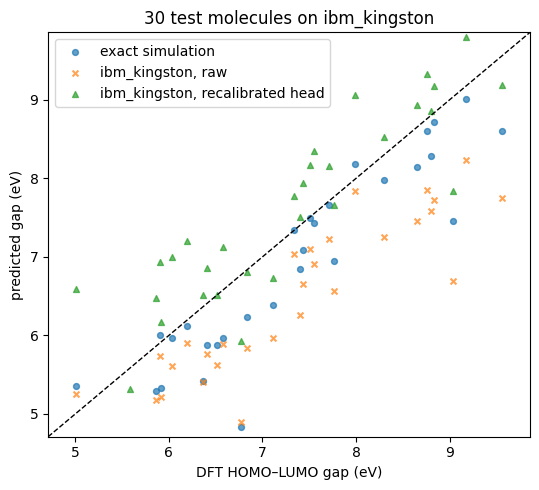

In [23]:
truth = y_test * Y_STD + Y_MEAN
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(truth, exact_test * Y_STD + Y_MEAN, s=18, alpha=0.7, label="exact simulation")
ax.scatter(truth, raw_test * Y_STD + Y_MEAN, s=18, alpha=0.7, marker="x", label=f"{backend.name}, raw")
ax.scatter(truth, recal_test * Y_STD + Y_MEAN, s=18, alpha=0.7, marker="^", label=f"{backend.name}, recalibrated head")
lim = [truth.min() - 0.3, truth.max() + 0.3]
ax.plot(lim, lim, "k--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("DFT HOMO–LUMO gap (eV)"); ax.set_ylabel("predicted gap (eV)")
ax.set_title(f"{len(test)} test molecules on {backend.name}"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RES_DIR, "ibm_hardware_scatter.png"), dpi=150)
plt.show()

## 5. Save

In [24]:
tag = "" if USE_REAL_HARDWARE else "_dryrun"
out = {
    "backend": backend.name, "real_hardware": USE_REAL_HARDWARE, "job_id": job.job_id(),
    "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "shots": SHOTS, "mitigation": bool(USE_REAL_HARDWARE and MITIGATION),
    "n_calibration": len(cal), "n_test": len(test),
    "two_qubit_gates_median": float(np.median(two_q)), "two_qubit_gates_max": int(max(two_q)),
    "depth_median": float(np.median(depth)),
    "test_mae_eV": summary, "recalibrated_head": [float(c) for c in coef],
}
json.dump(out, open(os.path.join(RES_DIR, f"ibm_hardware_results{tag}.json"), "w"), indent=2)
json.dump({str(k): counts[k] for k in mols}, open(os.path.join(RES_DIR, f"ibm_hardware_counts{tag}.json"), "w"))
print(json.dumps(out, indent=2))

{
  "backend": "ibm_kingston",
  "real_hardware": true,
  "job_id": "dbe496ngdj9s73fl68a0",
  "date_utc": "2026-10-24T05:44:25+00:00",
  "shots": 1024,
  "mitigation": true,
  "n_calibration": 30,
  "n_test": 30,
  "two_qubit_gates_median": 54.0,
  "two_qubit_gates_max": 104,
  "depth_median": 158.0,
  "test_mae_eV": {
    "exact simulation (same molecules)": 0.5239167809486389,
    "ibm_kingston, raw (1024 shots)": 0.8929107785224915,
    "ibm_kingston, recalibrated head": 0.5313625058148561
  },
  "recalibrated_head": [
    2.963898722734043,
    2.8212317934756337,
    -0.9272014824610575
  ]
}
